# Práctica 1 – Ingeniería del Conocimiento: Boosters, SVM y modelos ensamblados

Este cuaderno amplía la Fase 5 de la bitácora (`decisiones.md`). Responde a la indicación del profesor de probar **modelos ensamblados** (mezclar las predicciones de varios modelos con pesos) y modelos no vistos en clase, como gradient boosting. También cierra las pruebas de variables que quedaban pendientes.

Se usan las mismas particiones congeladas (KFold aleatorio 5x3, semilla 42), las mismas variables finales y el mismo criterio: una variante solo **mejora** si |media de la diferencia de RMSE| > su desviación entre los 15 folds. Todas las diferencias son emparejadas frente al modelo final de la Fase 5 (Ridge sobre log(precio) con splines y corrección de Duan).

| Pregunta | Sección |
|---|---|
| ¿Aportan algo las variables excluidas, el ratio envío/peso o las interacciones? | E.1 |
| ¿Algún booster moderno o un SVM supera al modelo final? | E.2 |
| ¿Fallan los modelos en productos distintos? | E.3 |
| ¿Mejora una mezcla con pesos fijos (80/20, 50/50)? | E.4 |
| ¿Mejora una mezcla con pesos aprendidos? | E.5 |
| ¿Cuándo sí ayuda mezclar? | E.6 |

In [1]:
# En Colab, LightGBM y XGBoost ya vienen instalados; CatBoost no:
# !pip install -q catboost
import time
import hashlib
import warnings
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt
import lightgbm
import xgboost
import catboost
from scipy.optimize import nnls
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, SplineTransformer
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import RepeatedKFold, KFold
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

SEED = 42

print('pandas', pd.__version__, '| numpy', np.__version__, '| scikit-learn', sklearn.__version__, '| scipy', scipy.__version__)
print('lightgbm', lightgbm.__version__, '| xgboost', xgboost.__version__, '| catboost', catboost.__version__)

pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | scipy 1.18.1
lightgbm 4.7.0 | xgboost 3.4.1 | catboost 1.2.10


## 0 Carga de datos
Se leen `train-1.csv` y `test-1.csv` de la misma carpeta que el cuaderno.

In [2]:
RUTA_DATOS = ''   # carpeta de los CSV; '' = misma carpeta que el cuaderno
tr = pd.read_csv(RUTA_DATOS + 'train-1.csv')

X = tr.drop(columns=['id', 'price']).copy()
y = tr['price'].to_numpy(dtype=float)
print('X:', X.shape)

X: (8000, 14)


## Definiciones
Mismas variables, misma corrección de Duan y mismas particiones que en las fases 3 a 5.

In [3]:
CAT_SEL = ['category', 'brand', 'season', 'channel']
NUMS = ['peso', 'rating', 'reviews', 'shipping_cost', 'margin', 'discount']


def variables(df):
    """Variables finales de la Fase 4: log(1 + peso) y log(1 + reviews). Transformaciones fila a fila (sin fuga)."""
    out = df[CAT_SEL].astype(str).copy()
    out['peso'] = np.log1p(df.weight_kg)
    out['rating'] = df.rating
    out['reviews'] = np.log1p(df.reviews)
    out['shipping_cost'] = df.shipping_cost
    out['margin'] = df.margin
    out['discount'] = df.discount
    return out


def lineal(modelo, splines, cats=CAT_SEL, nums=NUMS):
    """One-hot (drop='first') + numéricas estandarizadas [+ splines cúbicas de 5 nodos]."""
    tf = [('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), list(cats)),
          ('num', StandardScaler(), list(nums))]
    if splines:
        tf.append(('spl', SplineTransformer(n_knots=5, degree=3), list(nums)))
    return Pipeline([('prep', ColumnTransformer(tf)), ('model', modelo)])


def arboles(modelo):
    """Modelos de árboles: one-hot sin drop + numéricas sin escalar."""
    prep = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT_SEL),
                              ('num', 'passthrough', NUMS)])
    return Pipeline([('prep', prep), ('model', modelo)])


class LogDuan(RegressorMixin, BaseEstimator):
    """Entrena sobre log(price) y devuelve euros: factor * exp(pred), con el factor de Duan calculado
    sobre residuos fuera de muestra (CV interna de 5 folds, solo con datos de entrenamiento)."""
    def __init__(self, estimator, n_inner=5, seed=42):
        self.estimator = estimator
        self.n_inner = n_inner
        self.seed = seed

    def fit(self, X, y):
        ylog = np.log(np.asarray(y, dtype=float))
        self.est_ = clone(self.estimator).fit(X, ylog)
        oof = np.zeros_like(ylog)
        for a, b in KFold(self.n_inner, shuffle=True, random_state=self.seed).split(X):
            oof[b] = clone(self.estimator).fit(X.iloc[a], ylog[a]).predict(X.iloc[b])
        self.factor_ = float(np.mean(np.exp(ylog - oof)))
        return self

    def predict(self, X):
        return self.factor_ * np.exp(self.est_.predict(X))


def firma(splits):
    return hashlib.md5(np.concatenate([b for _, b in splits]).astype(np.int64).tobytes()).hexdigest()[:12]


SPLITS = list(RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEED).split(X))
assert firma(SPLITS) == '0589e8baabcf', 'Las particiones no coinciden con las de la Fase 2'
print('Particiones congeladas OK, huella', firma(SPLITS))

XF = variables(X)
RMSE = {}   # RMSE por fold de cada variante
OOF = {}    # predicciones fuera de muestra, una fila por repetición


def rmse_folds(pred):
    return np.array([np.sqrt(np.mean((pred[k // 5, b] - y[b]) ** 2)) for k, (_, b) in enumerate(SPLITS)])


def evaluar(nombre, est, Xf=None):
    """CV con las particiones congeladas. Guarda el RMSE por fold y las predicciones fuera de muestra (en euros)."""
    Xf = XF if Xf is None else Xf
    t0 = time.time()
    pred = np.full((3, len(y)), np.nan)
    for k, (a, b) in enumerate(SPLITS):
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            pred[k // 5, b] = clone(est).fit(Xf.iloc[a], y[a]).predict(Xf.iloc[b])
    OOF[nombre] = pred
    RMSE[nombre] = rmse_folds(pred)
    print(f'  {nombre}: RMSE {RMSE[nombre].mean():.3f} ({time.time() - t0:.0f} s)')


def tabla(filas, ref='Ridge log + splines (final)'):
    """filas: lista de (nombre, RMSE por fold). Diferencia emparejada frente a `ref` y veredicto con el criterio de siempre."""
    r = RMSE[ref]
    out = []
    for n, v in filas:
        dif = v - r
        m, s = dif.mean(), dif.std(ddof=1)
        if n == ref:
            ver = '(referencia)'
        elif m < 0 and abs(m) > s:
            ver = 'MEJORA'
        elif m > 0 and m > s:
            ver = 'EMPEORA'
        else:
            ver = 'EMPATE'
        out.append(dict(variante=n, RMSE=v.mean(), std=v.std(ddof=1), dif_media=m, dif_std=s,
                        folds_mejor=int((dif < 0).sum()), veredicto=ver))
    return pd.DataFrame(out).set_index('variante')


FINAL = 'Ridge log + splines (final)'
evaluar(FINAL, LogDuan(lineal(Ridge(alpha=0.01), splines=True)))

Particiones congeladas OK, huella 0589e8baabcf


  Ridge log + splines (final): RMSE 52.374 (2 s)


## E.1 Pruebas de variables pendientes
Quedaban sin medir desde las fases 2 y 4. Cada una se añade al modelo final, de una en una:
1. Volver al conjunto completo: `material` (faltantes como categoría «Desconocido»), `brand_tier`, `country` e `is_promo`.
2. El ratio `shipping_cost / weight_kg` (con log(1 + x), porque el ratio tiene cola larga).
3. La interacción `category × brand_tier`, como categórica cruzada.
4. La interacción `category × brand`.

In [4]:
ridge = Ridge(alpha=0.01)

Xc = XF.copy()
for c in ['material', 'brand_tier', 'country']:
    Xc[c] = X[c].fillna('Desconocido').astype(str)
Xc['is_promo'] = X.is_promo
evaluar('+ material, brand_tier, country, is_promo',
        LogDuan(lineal(ridge, True, cats=CAT_SEL + ['material', 'brand_tier', 'country'], nums=NUMS + ['is_promo'])), Xc)

Xr = XF.copy()
Xr['ratio'] = np.log1p(X.shipping_cost / X.weight_kg)
evaluar('+ log(1 + shipping_cost/weight_kg)', LogDuan(lineal(ridge, True, nums=NUMS + ['ratio'])), Xr)

Xi = XF.copy()
Xi['cat_tier'] = X.category.astype(str) + '|' + X.brand_tier.astype(str)
evaluar('+ category x brand_tier', LogDuan(lineal(ridge, True, cats=CAT_SEL + ['cat_tier'])), Xi)

Xi2 = XF.copy()
Xi2['cat_brand'] = X.category.astype(str) + '|' + X.brand.astype(str)
evaluar('+ category x brand', LogDuan(lineal(ridge, True, cats=CAT_SEL + ['cat_brand'])), Xi2)

VARS = [FINAL, '+ material, brand_tier, country, is_promo', '+ log(1 + shipping_cost/weight_kg)',
        '+ category x brand_tier', '+ category x brand']
print()
print(tabla([(n, RMSE[n]) for n in VARS]).round(3).to_string())

  + material, brand_tier, country, is_promo: RMSE 52.331 (3 s)


  + log(1 + shipping_cost/weight_kg): RMSE 52.395 (2 s)


  + category x brand_tier: RMSE 52.471 (2 s)


  + category x brand: RMSE 52.529 (2 s)

                                             RMSE    std  dif_media  dif_std  folds_mejor     veredicto
variante                                                                                               
Ridge log + splines (final)                52.374  4.913      0.000    0.000            0  (referencia)
+ material, brand_tier, country, is_promo  52.331  4.899     -0.044    0.098           10        EMPATE
+ log(1 + shipping_cost/weight_kg)         52.395  4.919      0.021    0.034            5        EMPATE
+ category x brand_tier                    52.471  4.901      0.097    0.121            3        EMPATE
+ category x brand                         52.529  4.887      0.154    0.211            3        EMPATE


## E.2 Boosters modernos y SVM
Todos sobre log(precio) con Duan fuera de muestra y las variables finales. Los hiperparámetros están **fijados a mano, sin búsqueda**: árboles poco profundos, porque en la Fase 5 el mejor GradientBoosting salió con profundidad 1. GradientBoosting y RandomForest son los de las fases 3 y 5. El SVM usa kernel RBF sobre las numéricas estandarizadas, con dos valores de C.

In [5]:
t_ini = time.time()
MODELOS = {
    'GradientBoosting (Fase 5)': arboles(GradientBoostingRegressor(
        learning_rate=0.1, max_depth=1, min_samples_leaf=5, subsample=0.7, n_estimators=1500,
        validation_fraction=0.1, n_iter_no_change=30, tol=1e-5, random_state=SEED)),
    'CatBoost (profundidad 3)': arboles(CatBoostRegressor(
        iterations=600, learning_rate=0.05, depth=3, random_seed=SEED, verbose=0, thread_count=2)),
    'LightGBM (4 hojas)': arboles(LGBMRegressor(
        n_estimators=500, learning_rate=0.03, num_leaves=4, min_child_samples=40, subsample=0.7,
        subsample_freq=1, colsample_bytree=0.7, random_state=SEED, verbose=-1, n_jobs=2)),
    'XGBoost (profundidad 2)': arboles(XGBRegressor(
        n_estimators=500, learning_rate=0.03, max_depth=2, min_child_weight=20, subsample=0.7,
        colsample_bytree=0.7, random_state=SEED, n_jobs=2)),
    'HGB (profundidad 2)': arboles(HistGradientBoostingRegressor(
        learning_rate=0.05, max_depth=2, max_iter=400, min_samples_leaf=40, random_state=SEED)),
    'LightGBM (por defecto)': arboles(LGBMRegressor(random_state=SEED, verbose=-1, n_jobs=2)),
    'SVM RBF (C=0.3)': lineal(SVR(C=0.3, epsilon=0.1, gamma='scale'), splines=False),
    'SVM RBF (C=1)': lineal(SVR(C=1.0, epsilon=0.1, gamma='scale'), splines=False),
    'RandomForest (Fase 3)': arboles(RandomForestRegressor(
        n_estimators=200, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=SEED)),
}
for n, est in MODELOS.items():
    evaluar(n, LogDuan(est))

IND = [FINAL] + list(MODELOS)
tab_ind = tabla([(n, RMSE[n]) for n in IND]).sort_values('RMSE')
print()
print(tab_ind.round(3).to_string())
print(f'\nTiempo: {time.time() - t_ini:.0f} s')

  GradientBoosting (Fase 5): RMSE 52.779 (77 s)


  CatBoost (profundidad 3): RMSE 52.863 (32 s)


  LightGBM (4 hojas): RMSE 53.115 (11 s)


  XGBoost (profundidad 2): RMSE 53.128 (12 s)


  HGB (profundidad 2): RMSE 53.139 (19 s)


  LightGBM (por defecto): RMSE 54.109 (9 s)


  SVM RBF (C=0.3): RMSE 54.709 (66 s)


  SVM RBF (C=1): RMSE 55.924 (92 s)


  RandomForest (Fase 3): RMSE 55.114 (79 s)

                               RMSE    std  dif_media  dif_std  folds_mejor     veredicto
variante                                                                                 
Ridge log + splines (final)  52.374  4.913      0.000    0.000            0  (referencia)
GradientBoosting (Fase 5)    52.779  4.933      0.405    0.374            1       EMPEORA
CatBoost (profundidad 3)     52.863  4.872      0.489    0.402            2       EMPEORA
LightGBM (4 hojas)           53.115  4.928      0.741    0.548            1       EMPEORA
XGBoost (profundidad 2)      53.128  4.854      0.754    0.461            1       EMPEORA
HGB (profundidad 2)          53.139  4.850      0.764    0.387            0       EMPEORA
LightGBM (por defecto)       54.109  4.727      1.735    0.429            0       EMPEORA
SVM RBF (C=0.3)              54.709  4.970      2.334    0.978            0       EMPEORA
RandomForest (Fase 3)        55.114  5.126      2.739  

## E.3 ¿Fallan los modelos en productos distintos?
Un ensamblado solo ayuda si los modelos se equivocan en sitios distintos: así, al promediar, los errores se compensan. Se mide con la correlación entre el error (predicción − precio real) de cada modelo y el del modelo final, sobre las predicciones fuera de muestra de la primera repetición. Cerca de 1 = fallan en los mismos productos.

Correlación de los errores con los del modelo final:
GradientBoosting (Fase 5)    0.991
CatBoost (profundidad 3)     0.990
LightGBM (4 hojas)           0.985
XGBoost (profundidad 2)      0.984
HGB (profundidad 2)          0.983
LightGBM (por defecto)       0.967
SVM RBF (C=0.3)              0.958
RandomForest (Fase 3)        0.952
SVM RBF (C=1)                0.941


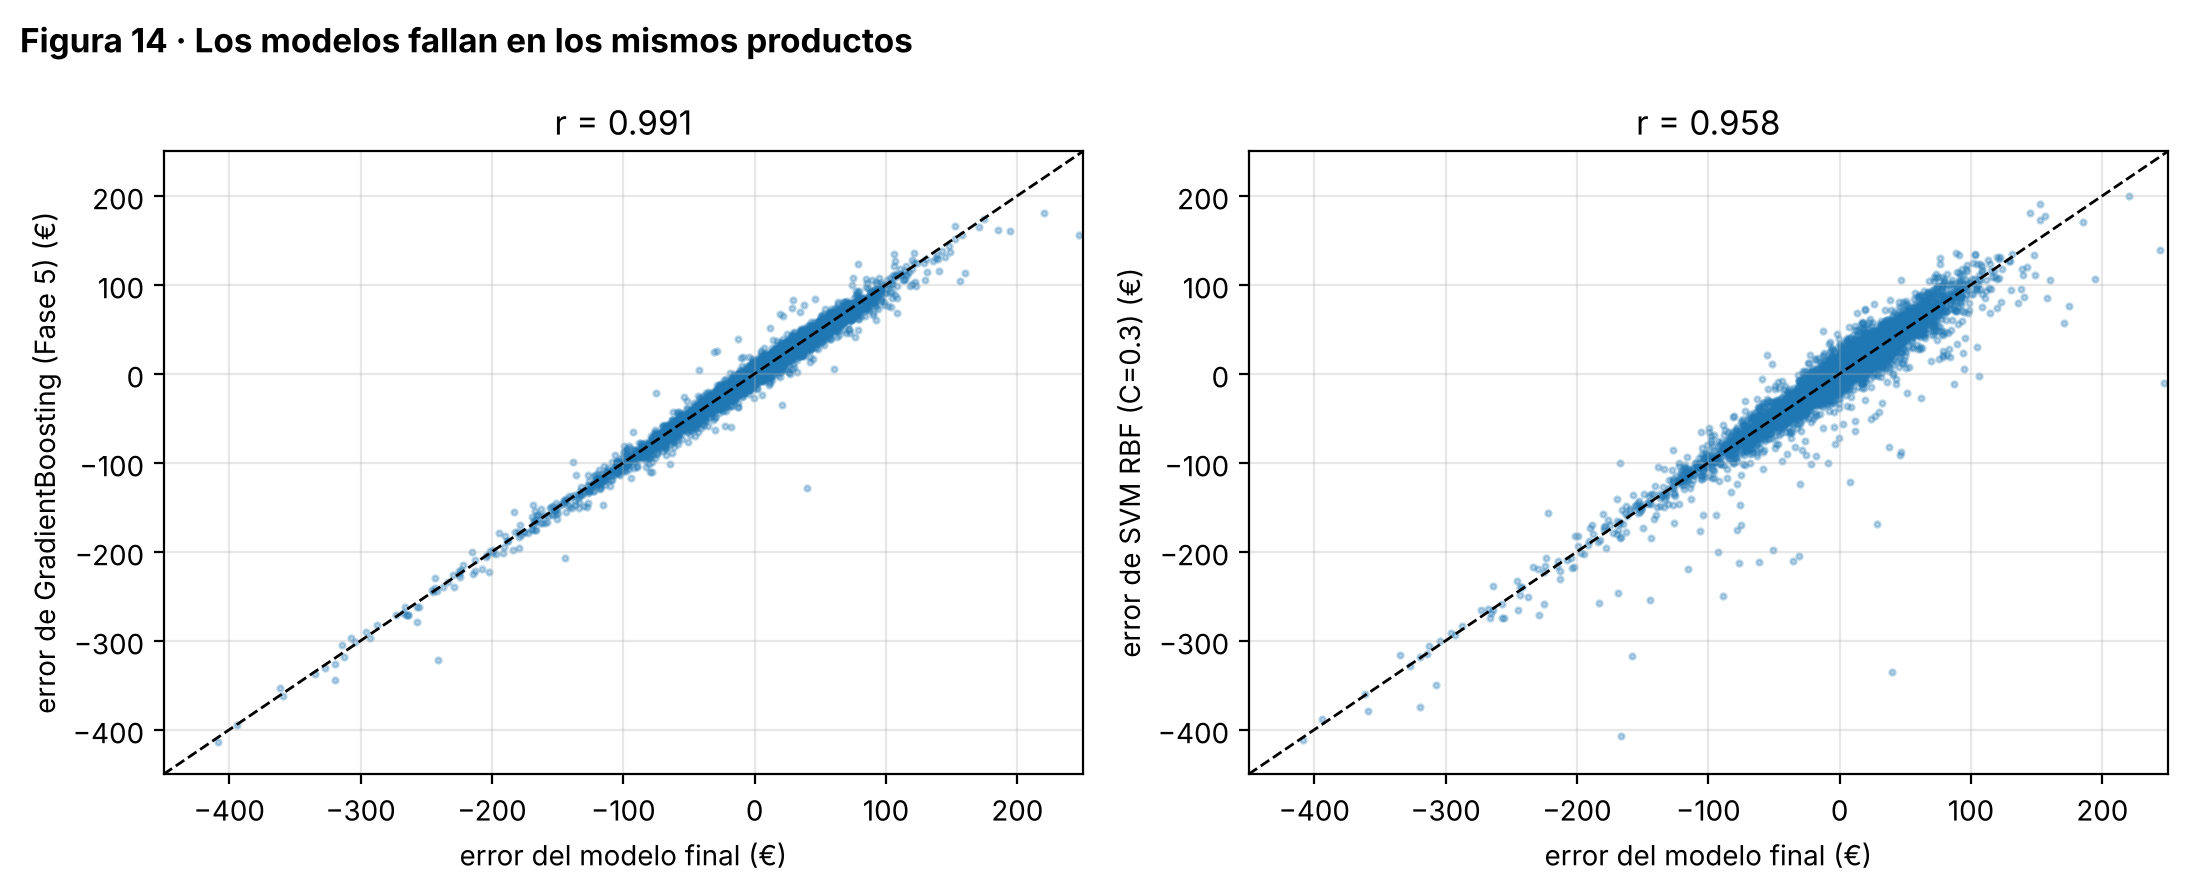

In [6]:
e_final = OOF[FINAL][0] - y
corr = pd.Series({n: np.corrcoef(OOF[n][0] - y, e_final)[0, 1] for n in MODELOS}).sort_values(ascending=False)
print('Correlación de los errores con los del modelo final:')
print(corr.round(3).to_string())

f, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, n in zip(ax, ['GradientBoosting (Fase 5)', 'SVM RBF (C=0.3)']):
    a.scatter(e_final, OOF[n][0] - y, s=4, alpha=.3)
    lim = [-450, 250]
    a.plot(lim, lim, 'k--', lw=1)
    a.set_xlim(lim); a.set_ylim(lim); a.grid(alpha=.3)
    a.set_xlabel('error del modelo final (€)'); a.set_ylabel(f'error de {n} (€)')
    a.set_title(f'r = {corr[n]:.3f}')
f.suptitle('Figura 14 · Los modelos fallan en los mismos productos', x=0.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

## E.4 Mezcla con pesos fijos
El ejemplo del profesor: dar un peso fijo a cada modelo, por ejemplo 80 % al mejor y 20 % al otro. Se prueba 80/20 y 50/50 del modelo final con cada uno de los demás.

In [7]:
filas = [(FINAL, RMSE[FINAL])]
for n in ['GradientBoosting (Fase 5)', 'CatBoost (profundidad 3)', 'LightGBM (4 hojas)', 'SVM RBF (C=0.3)', 'RandomForest (Fase 3)']:
    for w in [0.8, 0.5]:
        filas.append((f'{w:.0%} final + {1 - w:.0%} {n}', rmse_folds(w * OOF[FINAL] + (1 - w) * OOF[n])))
tab_fijos = tabla(filas)
print(tab_fijos.round(3).to_string())

                                             RMSE    std  dif_media  dif_std  folds_mejor     veredicto
variante                                                                                               
Ridge log + splines (final)                52.374  4.913      0.000    0.000            0  (referencia)
80% final + 20% GradientBoosting (Fase 5)  52.382  4.920      0.008    0.066            6        EMPATE
50% final + 50% GradientBoosting (Fase 5)  52.462  4.927      0.088    0.172            5        EMPATE
80% final + 20% CatBoost (profundidad 3)   52.388  4.902      0.013    0.073            5        EMPATE
50% final + 50% CatBoost (profundidad 3)   52.487  4.888      0.113    0.187            5        EMPATE
80% final + 20% LightGBM (4 hojas)         52.398  4.923      0.023    0.108            6        EMPATE
50% final + 50% LightGBM (4 hojas)         52.551  4.931      0.176    0.268            4        EMPATE
80% final + 20% SVM RBF (C=0.3)            52.462  4.947      0.

## E.5 Mezcla con pesos aprendidos
En vez de fijar los pesos a ojo, se aprenden: mínimos cuadrados no negativos sobre las predicciones fuera de muestra, normalizados para que sumen 1.

Para no hacer trampa, los pesos de cada fold se ajustan **solo con los otros cuatro folds** de la misma repetición y se aplican al fold que se evalúa. Si se eligieran mirando los mismos folds que luego se puntúan, la mezcla saldría favorecida.

In [8]:
def mezcla_aprendida(nombres):
    pred = np.full((3, len(y)), np.nan)
    pesos = []
    for k, (_, b) in enumerate(SPLITS):
        r = k // 5
        otros = np.concatenate([SPLITS[j][1] for j in range(5 * r, 5 * r + 5) if j != k])
        w, _ = nnls(np.column_stack([OOF[n][r, otros] for n in nombres]), y[otros])
        w = w / w.sum()
        pesos.append(w)
        pred[r, b] = np.column_stack([OOF[n][r, b] for n in nombres]) @ w
    return rmse_folds(pred), np.mean(pesos, axis=0)


BOOSTERS = ['GradientBoosting (Fase 5)', 'CatBoost (profundidad 3)', 'LightGBM (4 hojas)', 'XGBoost (profundidad 2)', 'HGB (profundidad 2)']
COMBOS = {'final + GradientBoosting': [FINAL, 'GradientBoosting (Fase 5)'],
          'final + CatBoost': [FINAL, 'CatBoost (profundidad 3)'],
          'final + SVM': [FINAL, 'SVM RBF (C=0.3)'],
          'final + RandomForest': [FINAL, 'RandomForest (Fase 3)'],
          'final + 5 boosters': [FINAL] + BOOSTERS,
          'los 10 modelos': IND}
filas, peso_final = [(FINAL, RMSE[FINAL])], {}
for nombre, comp in COMBOS.items():
    r, w = mezcla_aprendida(comp)
    filas.append((nombre, r))
    peso_final[nombre] = w[comp.index(FINAL)]
tab_apr = tabla(filas)
tab_apr['peso_medio_final'] = pd.Series(peso_final)
print(tab_apr.round(3).to_string())

                               RMSE    std  dif_media  dif_std  folds_mejor     veredicto  peso_medio_final
variante                                                                                                   
Ridge log + splines (final)  52.374  4.913      0.000    0.000            0  (referencia)               NaN
final + GradientBoosting     52.379  4.906      0.004    0.030            5        EMPATE             0.901
final + CatBoost             52.391  4.913      0.017    0.029            2        EMPATE             0.934
final + SVM                  52.395  4.919      0.021    0.031            1        EMPATE             0.979
final + RandomForest         52.383  4.925      0.008    0.019            0        EMPATE             0.992
final + 5 boosters           52.404  4.899      0.030    0.045            4        EMPATE             0.850
los 10 modelos               52.414  4.903      0.039    0.053            3        EMPATE             0.846


## E.6 ¿Cuándo sí ayuda mezclar?
Las mismas mezclas aprendidas, pero **sin** el modelo final: entre modelos de calidad parecida. Se compara cada mezcla con su mejor componente.

In [9]:
filas = []
for nombre, comp in {'RandomForest + SVM': ['RandomForest (Fase 3)', 'SVM RBF (C=0.3)'],
                     'CatBoost + GradientBoosting': ['CatBoost (profundidad 3)', 'GradientBoosting (Fase 5)'],
                     '5 boosters': BOOSTERS}.items():
    r, w = mezcla_aprendida(comp)
    mejor = min(comp, key=lambda n: RMSE[n].mean())
    dif = r - RMSE[mejor]
    filas.append(dict(mezcla=nombre, RMSE_mezcla=r.mean(), mejor_componente=RMSE[mejor].mean(),
                      dif_vs_componente=dif.mean(), dif_std=dif.std(ddof=1),
                      dif_vs_final=(r - RMSE[FINAL]).mean()))
print(pd.DataFrame(filas).set_index('mezcla').round(3).to_string())

                             RMSE_mezcla  mejor_componente  dif_vs_componente  dif_std  dif_vs_final
mezcla                                                                                              
RandomForest + SVM                54.283            54.709             -0.426    0.342         1.908
CatBoost + GradientBoosting       52.724            52.779             -0.056    0.154         0.349
5 boosters                        52.753            52.779             -0.026    0.175         0.379


## Conclusiones

- **Variables (E.1):** ni el conjunto completo, ni el ratio envío/peso, ni las interacciones de categoría con marca o tier cambian el RMSE más allá del ruido. Se mantiene el conjunto de la Fase 4.
- **Modelos (E.2):** ningún booster ni el SVM supera al modelo final. Los que más se acercan son los de árboles muy poco profundos, lo que encaja con que el precio sea aditivo en logaritmos.
- **Ensamblados (E.3–E.5):** los errores de todos los modelos están muy correlacionados con los del modelo final, así que no hay errores que compensar. Ninguna mezcla mejora, ni con pesos fijos ni aprendidos; cuando se aprenden, el modelo final se lleva casi todo el peso.
- **Cuándo sí ayuda (E.6):** entre modelos de calidad parecida y errores algo distintos (RandomForest + SVM) la mezcla mejora a su mejor componente, pero sigue por detrás del modelo final.

**Decisión:** el modelo final no cambia (Ridge sobre log(precio) con splines y corrección de Duan, sin mezcla) y el fichero de entrega tampoco.

**Límites:** boosters y SVM sin búsqueda de hiperparámetros; no se ha probado stacking con un metamodelo no lineal ni la mezcla en escala logarítmica.